# 02 — Feed-forward network (deliverable 1)

A feed-forward network built from PyTorch primitives (`nn.Module`, `nn.Linear`, our own training loop in `museum/train.py`):

1. The architecture, and its parameter count by hand.
2. The initialisation check: the initial loss must be ln 5.
3. A baseline training run at 64 px, with its learning curves.
4. The input-size sweep (32 / 64 / 128 px), 3 seeds each.

Everything is measured on the **validation** set; the test set is only used in `07_comparison`. Diagnosis and fixes come in `03_diagnosis`.

In [1]:
import math
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

sys.path.insert(0, "../src")
from museum.data import ROOT, get_loaders
from museum.models import StyleMLP, count_parameters
from museum.train import evaluate, fit, get_device

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: 1 seed and a few epochs, for a quick check
EPOCHS = 8 if FAST_RUN else 40
SEEDS = [0] if FAST_RUN else [0, 1, 2]
SIZES = [32, 64, 128]
HIDDEN = (256, 128)
BATCH_SIZE = 64
LR = 1e-3

torch.manual_seed(0)
device = get_device()
loss_fn = nn.CrossEntropyLoss()
FIG_DIR = ROOT / "results" / "figures"
print("device:", device, "| FAST_RUN:", FAST_RUN, "| epochs:", EPOCHS, "| seeds:", SEEDS)

device: mps | FAST_RUN: False | epochs: 40 | seeds: [0, 1, 2]


## 1. The architecture

`StyleMLP` flattens the RGB image into one vector, then applies hidden `Linear → ReLU` layers and a final `Linear` giving one score (logit) per style. Baseline: two hidden layers of 256 and 128 units, no dropout.

In [2]:
model = StyleMLP(img_size=64, hidden=HIDDEN)
print(model)

StyleMLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=5, bias=True)
  )
)


**Parameter count by hand.** A `Linear(n_in, n_out)` layer has a weight matrix `n_in × n_out` and `n_out` biases, so `(n_in + 1) × n_out` parameters. At 64 px the input has 3 × 64 × 64 = 12,288 values.

In [3]:
def layer_sizes(img_size, hidden=HIDDEN, n_classes=5):
    return [3 * img_size * img_size, *hidden, n_classes]


def params_by_hand(img_size, hidden=HIDDEN):
    sizes = layer_sizes(img_size, hidden)
    return sum((n_in + 1) * n_out for n_in, n_out in zip(sizes[:-1], sizes[1:], strict=True))


sizes = layer_sizes(64)
breakdown = pd.DataFrame(
    [{"layer": f"Linear({n_in:,} → {n_out})", "weights": n_in * n_out, "biases": n_out,
      "parameters": (n_in + 1) * n_out} for n_in, n_out in zip(sizes[:-1], sizes[1:], strict=True)]
)
breakdown["share"] = (breakdown["parameters"] / breakdown["parameters"].sum()).map("{:.1%}".format)
assert params_by_hand(64) == count_parameters(model) == breakdown["parameters"].sum()
print(f"total at 64 px: {params_by_hand(64):,} parameters = {4 * params_by_hand(64) / 1e6:.1f} MB in float32")
breakdown

total at 64 px: 3,179,525 parameters = 12.7 MB in float32


,layer,weights,biases,parameters,share
0,"Linear(12,288 → 256)",3145728,256,3145984,98.9%
1,Linear(256 → 128),32768,128,32896,1.0%
2,Linear(128 → 5),640,5,645,0.0%


In [4]:
per_size = pd.DataFrame({
    "inputs": [3 * s * s for s in SIZES],
    "parameters": [params_by_hand(s) for s in SIZES],
    "size (MB, float32)": [round(4 * params_by_hand(s) / 1e6, 1) for s in SIZES],
}, index=[f"{s} px" for s in SIZES])
for s in SIZES:
    assert params_by_hand(s) == count_parameters(StyleMLP(img_size=s, hidden=HIDDEN))
per_size

,inputs,parameters,"size (MB, float32)"
32 px,3072,820229,3.3
64 px,12288,3179525,12.7
128 px,49152,12616709,50.5


**What we see.**
- The first layer holds 98.9 % of the parameters: the size of the network is set by the size of the image.
- Doubling the side of the image multiplies the inputs, and so the first layer, by 4: 0.8 M parameters at 32 px, 3.2 M at 64 px, 12.6 M at 128 px. At 128 px that is 50 MB, half of the director's 100 MB footprint budget.

## 2. Initialisation check

Hidden layers use **He initialisation** (weights with std √(2 / n_in)), which keeps the scale of the activations roughly constant through ReLU layers. The output layer is then **scaled by 0.01**, so the initial logits are almost equal: the network starts with no preference between the 5 styles, and the cross-entropy should be −log(1/5) = ln 5 ≈ 1.609. For comparison, the same network without the 0.01 scaling.

In [5]:
_, val_dl_64, _, _ = get_loaders(img_size=64, batch_size=BATCH_SIZE)

torch.manual_seed(0)
scaled = StyleMLP(img_size=64, hidden=HIDDEN).to(device)
torch.manual_seed(0)
unscaled = StyleMLP(img_size=64, hidden=HIDDEN)
nn.init.kaiming_normal_(unscaled.layers[-1].weight, nonlinearity="relu")   # undo the 0.01 scaling
unscaled = unscaled.to(device)

loss_scaled, _ = evaluate(scaled, val_dl_64, loss_fn, device)
loss_unscaled, _ = evaluate(unscaled, val_dl_64, loss_fn, device)
print(f"ln 5 = {math.log(5):.4f}")
print(f"initial validation loss, output layer x 0.01: {loss_scaled:.4f}")
print(f"initial validation loss, plain He output layer: {loss_unscaled:.4f}")
assert abs(loss_scaled - math.log(5)) < 0.05

ln 5 = 1.6094
initial validation loss, output layer x 0.01: 1.6083
initial validation loss, plain He output layer: 2.5127


**What we see.**
- With the 0.01 scaling, the initial loss is 1.608, as expected (ln 5 = 1.609).
- Without it, the loss starts at 2.51: the network makes confident, random predictions, and the first epochs are spent undoing that confidence instead of learning.

## 3. Baseline at 64 px

Adam (learning rate 1e-3), batches of 64, no regularisation, no augmentation, 40 epochs. The learning rate is studied in `03_diagnosis`.

40 epochs in 3.6 s
lowest validation loss: 1.512 at epoch 2
best validation accuracy: 0.422 at epoch 15
last epoch: train acc 0.967, val acc 0.409, val loss 3.879


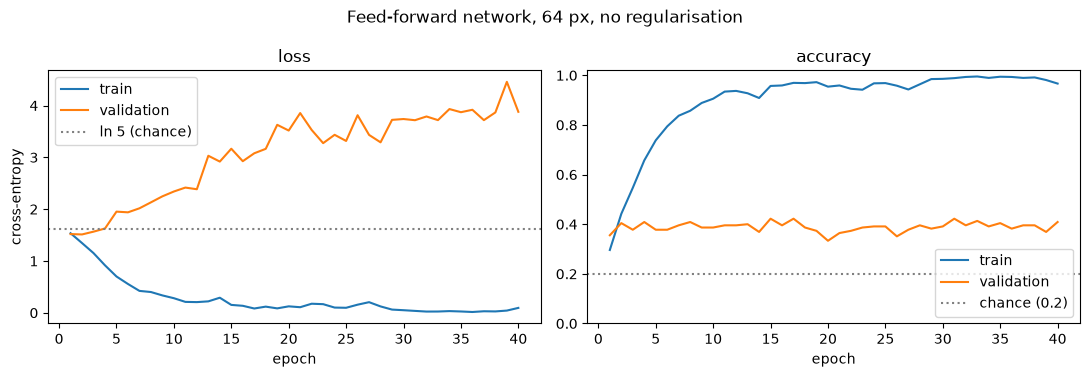

In [6]:
train_dl, val_dl, _, classes = get_loaders(img_size=64, batch_size=BATCH_SIZE, seed=0)
torch.manual_seed(0)
baseline = StyleMLP(img_size=64, hidden=HIDDEN)
optimizer = torch.optim.Adam(baseline.parameters(), lr=LR)
history = fit(baseline, train_dl, val_dl, loss_fn, optimizer, EPOCHS, device, verbose=False)

best = int(np.argmax(history["val_acc"]))
print(f"{EPOCHS} epochs in {sum(history['epoch_time']):.1f} s")
print(f"lowest validation loss: {min(history['val_loss']):.3f} at epoch {history['best_epoch']}")
print(f"best validation accuracy: {history['val_acc'][best]:.3f} at epoch {best + 1}")
print(f"last epoch: train acc {history['train_acc'][-1]:.3f}, val acc {history['val_acc'][-1]:.3f}, "
      f"val loss {history['val_loss'][-1]:.3f}")

epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="validation")
axes[0].axhline(math.log(5), color="grey", ls=":", label="ln 5 (chance)")
axes[0].set(title="loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].plot(epochs, history["train_acc"], label="train")
axes[1].plot(epochs, history["val_acc"], label="validation")
axes[1].axhline(0.2, color="grey", ls=":", label="chance (0.2)")
axes[1].set(title="accuracy", xlabel="epoch", ylim=(0, 1.02))
for ax in axes:
    ax.legend()
fig.suptitle("Feed-forward network, 64 px, no regularisation")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_baseline_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.**
- **Training set:** the loss falls towards 0, and the accuracy reaches 97 %.
- **Validation set:**
  - The loss is lowest at **epoch 2** (1.51), then climbs to about 3.9, more than twice the loss of a uniform guess (ln 5).
  - The accuracy stays between about 0.33 and 0.42 from epoch 2 onwards, peaking at 0.42 (chance is 0.20).

**Why.** This is **overfitting**: with 3.2 M parameters for 1,050 images (about 3,000 per image), the network memorises the training images instead of learning what makes a style.

**Loss and accuracy disagree.** The validation loss rises while the validation accuracy stays flat: the network becomes very confident on the validation images it gets wrong, while the share it gets right barely moves. Early stopping on the validation loss would stop at epoch 2.

Diagnosis and fixes: `03_diagnosis` and the ablation (A7).

## 4. Input-size sweep

Same network and training at 32, 64 and 128 px, 3 seeds each (the seed sets the initial weights and the batch order). For each run:
- **best val acc:** the highest validation accuracy over the epochs.
- **val acc at lowest val loss:** what early stopping on the validation loss would keep.
- **train acc:** at the last epoch.

**Rule, fixed before looking at the results:** keep the size with the highest mean best val acc, unless a smaller size is within one standard deviation of it; then keep the smaller one, since it is cheaper and faster.

In [7]:
runs = []
for size in SIZES:
    for seed in SEEDS:
        train_dl, val_dl, _, _ = get_loaders(img_size=size, batch_size=BATCH_SIZE, seed=seed)
        torch.manual_seed(seed)
        model = StyleMLP(img_size=size, hidden=HIDDEN)
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
        start = time.perf_counter()
        h = fit(model, train_dl, val_dl, loss_fn, optimizer, EPOCHS, device, verbose=False)
        runs.append({
            "size": size, "seed": seed,
            "best val acc": max(h["val_acc"]),
            "val acc at lowest val loss": h["val_acc"][h["best_epoch"] - 1],
            "lowest val loss": min(h["val_loss"]),
            "train acc": h["train_acc"][-1],
            "train time (s)": time.perf_counter() - start,
        })
        print(f"{size:>3} px, seed {seed}: best val acc {runs[-1]['best val acc']:.3f}, "
              f"train acc {runs[-1]['train acc']:.3f}, {runs[-1]['train time (s)']:.1f} s")
runs = pd.DataFrame(runs)

 32 px, seed 0: best val acc 0.436, train acc 0.989, 2.5 s


 32 px, seed 1: best val acc 0.431, train acc 0.973, 2.2 s


 32 px, seed 2: best val acc 0.422, train acc 0.989, 2.2 s


 64 px, seed 0: best val acc 0.422, train acc 0.967, 3.6 s


 64 px, seed 1: best val acc 0.427, train acc 0.958, 3.6 s


 64 px, seed 2: best val acc 0.427, train acc 0.974, 4.2 s


128 px, seed 0: best val acc 0.409, train acc 0.942, 13.4 s


128 px, seed 1: best val acc 0.418, train acc 0.969, 13.3 s


128 px, seed 2: best val acc 0.409, train acc 0.987, 13.3 s


highest mean best val acc: 32 px (0.430 ± 0.007) -> chosen size: 32 px


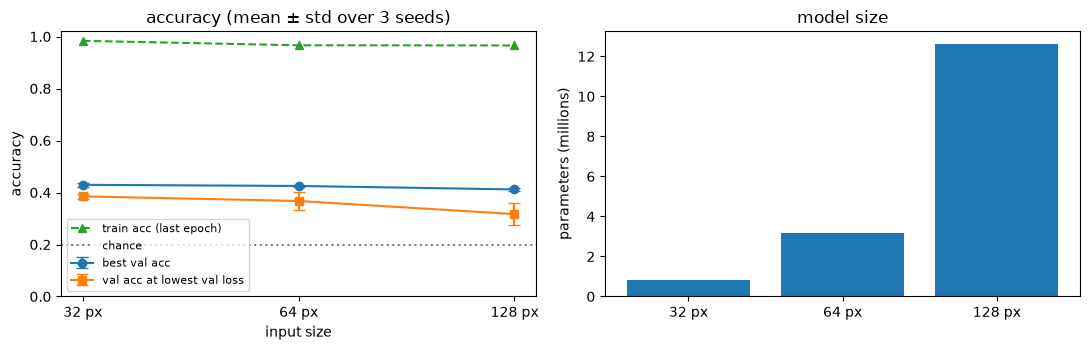

,parameters,best val acc (mean),best val acc (std),val acc at lowest val loss (mean),val acc at lowest val loss (std),lowest val loss (mean),lowest val loss (std),train acc (mean),train acc (std),train time (s) (mean),train time (s) (std)
size,,,,,,,,,,,
32,820229,0.430,0.007,0.385,0.009,1.462,0.017,0.983,0.009,2.282,0.196
64,3179525,0.425,0.003,0.367,0.033,1.494,0.016,0.966,0.008,3.807,0.361
128,12616709,0.412,0.005,0.317,0.043,1.543,0.032,0.966,0.023,13.363,0.067


In [8]:
summary = runs.groupby("size").agg(["mean", "std"]).drop(columns="seed")
summary.columns = [f"{metric} ({stat})" for metric, stat in summary.columns]
summary.insert(0, "parameters", [params_by_hand(s) for s in summary.index])

mean, std = summary["best val acc (mean)"], summary["best val acc (std)"].fillna(0)
top = int(mean.idxmax())
chosen = min(s for s in SIZES if mean[s] >= mean[top] - std[top])
print(f"highest mean best val acc: {top} px ({mean[top]:.3f} ± {std[top]:.3f}) -> chosen size: {chosen} px")

x = np.arange(len(SIZES))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].errorbar(x, mean, yerr=std, marker="o", capsize=4, label="best val acc")
axes[0].errorbar(x, summary["val acc at lowest val loss (mean)"],
                 yerr=summary["val acc at lowest val loss (std)"].fillna(0), marker="s", capsize=4,
                 label="val acc at lowest val loss")
axes[0].plot(x, summary["train acc (mean)"], marker="^", ls="--", label="train acc (last epoch)")
axes[0].axhline(0.2, color="grey", ls=":", label="chance")
axes[0].set(xticks=x, xticklabels=[f"{s} px" for s in SIZES], xlabel="input size", ylabel="accuracy",
            ylim=(0, 1.02), title=f"accuracy (mean ± std over {len(SEEDS)} seeds)")
axes[0].legend(fontsize=8)
axes[1].bar([f"{s} px" for s in SIZES], summary["parameters"] / 1e6)
axes[1].set(ylabel="parameters (millions)", title="model size")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_input_size_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

summary.round(3)

**What we see.**
- **Larger images don't help.** Best validation accuracy is 0.430 ± 0.007 at 32 px, 0.425 ± 0.003 at 64 px and 0.412 ± 0.005 at 128 px. 128 px is the lowest for all three seeds.
- **Every size overfits the same way** (train accuracy 97–98 %).
- **Larger networks get overconfident faster.** The accuracy kept by early stopping on the loss drops with size (0.385 → 0.317) and varies more between seeds.
- **The cost grows fast.** From 32 to 128 px: 15× more parameters and about 6× the training time.

**Why.** A feed-forward network treats every pixel as a separate input. More pixels means more weights to fit with the same 1,050 images, and the network has no notion that neighbouring pixels belong together, or that the same brushstroke can appear anywhere in the painting. The fine detail of 128 px is wasted on it; at 32 px it still sees the colours and the rough composition, which is what it actually uses.

**Decision** (rule fixed above): **32 px**, the most accurate and the cheapest. The rest of the FFN work (`03_diagnosis`, ablation A7) uses 32 px.

## Summary

- **The network.** `StyleMLP`: flatten → 256 → 128 → 5, He initialisation, output layer × 0.01 (initial loss 1.608 ≈ ln 5).
- **The baseline overfits.** Without regularisation, it reaches about 43 % validation accuracy at best (chance: 20 %) while fitting the training images almost perfectly.
- **Input size.** 32 px does as well as 64 or 128 px with up to 15× fewer parameters, so we continue at 32 px.
- **About the metric.** "Best val acc" is the maximum over 40 epochs, so slightly optimistic. The ablation (A7) uses early stopping and reports the epoch it keeps.
- **Next.** `03_diagnosis`: initial-loss and one-batch checks, learning-rate sweep, overfitting diagnosis. Then the ablation (A7): dropout, weight decay, augmentation, early stopping.